In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the processed chronic health dataset

df = pd.read_csv("../../data/processed/chronic_sample.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (20000, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,0.0,0.0,1.0,21.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,3.0,7.0,0.0,0.0,7.0,4.0,2.0
1,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,13.0,6.0,6.0
2,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,4.0,7.0
3,0.0,0.0,0.0,1.0,27.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,3.0,0.0,0.0,1.0,2.0,4.0,7.0
4,0.0,0.0,1.0,1.0,31.0,1.0,0.0,0.0,0.0,1.0,...,1.0,1.0,4.0,27.0,27.0,1.0,0.0,8.0,3.0,2.0


In [3]:
# Inspect dataset information

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts())

Column names:
['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_012          20000 non-null  float64
 1   HighBP                20000 non-null  float64
 2   HighChol              20000 non-null  float64
 3   CholCheck             20000 non-null  float64
 4   BMI                   20000 non-null  float64
 5   Smoker                20000 non-null  float64
 6   Stroke                20000 non-null  float64
 7   HeartDiseaseorAttack  20000 non-null  float64
 8   PhysActivity          20000 non-null  float64
 9   Fruits                2

In [4]:
# Select all input features except the target

target = 'Diabetes_012'

X = df.drop(columns=[target])
y = df[target]

print("Number of features:", X.shape[1])
print("Feature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Number of features: 21
Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target distribution:
Diabetes_012
0.0    16874
2.0     2752
1.0      374
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16000
Testing samples: 4000


In [6]:
target = 'Diabetes_012'

X = df.drop(columns=[target])
y = df[target]

print("Total input features:", X.shape[1])
print("Target classes:", sorted(y.unique()))
print("Feature names:")
print(X.columns.tolist())

Total input features: 21
Target classes: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
Feature names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16000, 21)
Testing data: (4000, 21)


In [8]:
# Create the Decision Tree classifier

dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [9]:
# Predict using the trained Decision Tree model

y_pred = dt_model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 actual values:
[0. 0. 0. 2. 0. 2. 0. 0. 0. 0.]

First 10 predicted values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [10]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 76.2 %


In [11]:
# Generate classification report

print("Decision Tree Classification Report\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

Decision Tree Classification Report

              precision    recall  f1-score   support

 No Diabetes       0.88      0.85      0.86      3375
 Prediabetes       0.05      0.07      0.06        75
    Diabetes       0.28      0.32      0.30       550

    accuracy                           0.76      4000
   macro avg       0.40      0.41      0.41      4000
weighted avg       0.78      0.76      0.77      4000



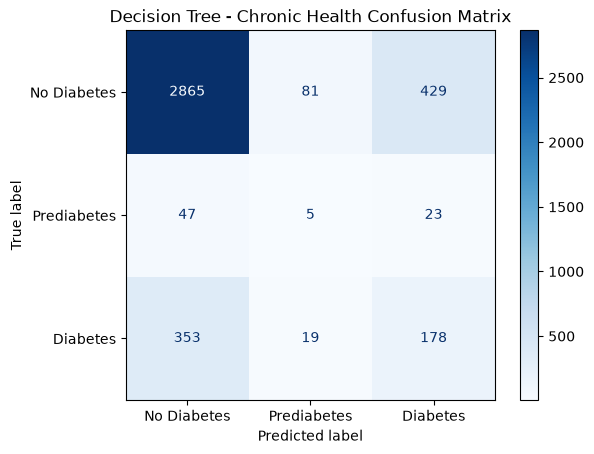

In [12]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Chronic Health Confusion Matrix")
plt.show()

In [13]:
# Hyperparameter tuning for Decision Tree

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, 12, 15, None],
    'min_samples_split': [2, 10, 20, 50, 100],
    'min_samples_leaf': [1, 5, 10, 20, 50],
    'class_weight': [None, 'balanced']
}

dt = DecisionTreeClassifier(random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_grid,
    n_iter=30,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(random_search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'min_samples_split': 10, 'min_samples_leaf': 5, 'max_depth': None, 'criterion': 'entropy', 'class_weight': None}

Best Cross-Validation Macro F1:
0.4086


In [14]:
# Get the best Decision Tree model

best_dt_model = random_search.best_estimator_

# Make predictions
y_pred_tuned = best_dt_model.predict(X_test)

# Calculate accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned Decision Tree Accuracy:",
      round(tuned_accuracy * 100, 2), "%")

# Classification report
print("\nTuned Decision Tree Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

Tuned Decision Tree Accuracy: 81.73 %

Tuned Decision Tree Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.87      0.93      0.90      3375
 Prediabetes       0.00      0.00      0.00        75
    Diabetes       0.35      0.26      0.30       550

    accuracy                           0.82      4000
   macro avg       0.41      0.40      0.40      4000
weighted avg       0.78      0.82      0.80      4000



In [15]:
# Compare both Decision Tree models

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1'],
    'Default Decision Tree': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='macro', zero_division=0),
        recall_score(y_test, y_pred, average='macro', zero_division=0),
        f1_score(y_test, y_pred, average='macro', zero_division=0)
    ],
    'Tuned Decision Tree': [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned, average='macro', zero_division=0),
        recall_score(y_test, y_pred_tuned, average='macro', zero_division=0),
        f1_score(y_test, y_pred_tuned, average='macro', zero_division=0)
    ]
})

comparison.round(4)


,Metric,Default Decision Tree,Tuned Decision Tree
0,Accuracy,0.7620,0.8172
1,Macro Precision,0.4025,0.4085
2,Macro Recall,0.4131,0.3959
3,Macro F1,0.4067,0.3996


In [18]:
# {'Default Random Forest': {'Accuracy': 0.8445, 'Macro F1': 0.39455828204236393, 'Macro Recall': 0.38537373737373737}, 'Balanced Random Forest': {'Accuracy': 0.804, 'Macro F1': 0.4428037979570085, 'Macro Recall': 0.46525252525252525}}

rf_results = {
    "Default Random Forest": {
        "Accuracy": 0.8445,
        "Macro F1": 0.3946,
        "Macro Recall": 0.3854
    },
    "Balanced Random Forest": {
        "Accuracy": 0.8040,
        "Macro F1": 0.4428,
        "Macro Recall": 0.4653
    }
}

In [19]:
# Final Decision Tree vs Random Forest comparison

final_comparison = pd.DataFrame([
    {
        "Model": "Default Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred, average="macro")
    },
    {
        "Model": "Tuned Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Macro F1": f1_score(y_test, y_pred_tuned, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred_tuned, average="macro")
    },
    *[
        {"Model": name, **metrics}
        for name, metrics in rf_results.items()
    ]
])

final_comparison.round(4)

,Model,Accuracy,Macro F1,Macro Recall
0,Default Decision Tree,0.7620,0.4067,0.4131
1,Tuned Decision Tree,0.8172,0.3996,0.3959
2,Default Random Forest,0.8445,0.3946,0.3854
3,Balanced Random Forest,0.8040,0.4428,0.4653


In [20]:
# Try custom class weights for Decision Tree

custom_dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=2,
    class_weight={
        0: 1,
        1: 15,
        2: 3
    },
    random_state=42
)

custom_dt.fit(X_train, y_train)

custom_pred = custom_dt.predict(X_test)

print("Custom Weighted Decision Tree Accuracy:",
      round(accuracy_score(y_test, custom_pred) * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    custom_pred,
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

Custom Weighted Decision Tree Accuracy: 71.83 %

Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.91      0.77      0.84      3375
 Prediabetes       0.03      0.16      0.05        75
    Diabetes       0.35      0.47      0.40       550

    accuracy                           0.72      4000
   macro avg       0.43      0.47      0.43      4000
weighted avg       0.82      0.72      0.76      4000

